# Stochastic SINDy (SSISDE): Black–Scholes experiment

Run all cells from a fresh Python 3.10–3.12 kernel (tested locally with 3.11).
The functions in `data_generation/` and `models/` use explicit inputs and outputs.
The calculations, settings, and order of the original experiment are preserved.

Local VS Code: select `.venv/bin/python`. Colab in VS Code: select **Colab → Auto
Connect**. A remote runtime needs its own copy of the scripts; the setup cell
downloads the private repository when it is not already present, asking for a
GitHub token through a hidden input. Use a fine-grained token with read-only
Contents access to `munawarali93/SSISDE`. Do not paste a token into a code cell.
An existing runtime checkout is reused; restart/delete it to fetch newer code.

Figures keep their original filenames and are saved in `experiments/black_scholes/`.
The untouched input notebook is in `original/`. See `README.md` for setup details.

Compare three final SSISDE fits, using noise from Method 1, Method 2 and ODE2. Each fit uses the same degree-5 libraries, seven-fold cross-validation and seven elastic-net mixing values. The final table reports noise, drift and diffusion errors.


In [1]:
from pathlib import Path
import os
import sys

if not (3, 10) <= sys.version_info[:2] < (3, 13):
    raise RuntimeError("The original dependency pins require Python 3.10–3.12; use the local .venv or a compatible Colab runtime.")

def _find_project():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]:
        if (candidate / 'models/stochastic_sindy.py').is_file() and (candidate / 'requirements.txt').is_file():
            return candidate
    return None

PROJECT_ROOT = _find_project()
if PROJECT_ROOT is None:
    import importlib.util
    try:
        _in_colab = importlib.util.find_spec('google.colab') is not None
    except ModuleNotFoundError:
        _in_colab = False
    if not _in_colab:
        raise FileNotFoundError("Open this notebook from the SSISDE checkout so its Python scripts are available.")

    def _download_private_project():
        from getpass import getpass
        from io import BytesIO
        from urllib.request import Request, urlopen
        from zipfile import ZipFile
        token = getpass('GitHub token (read-only Contents access to SSISDE): ')
        try:
            request = Request(
                'https://api.github.com/repos/munawarali93/SSISDE/zipball/main',
                headers={'Authorization': f'Bearer {token}', 'Accept': 'application/vnd.github+json'},
            )
            with urlopen(request, timeout=120) as response:
                archive_bytes = response.read()
        finally:
            token = None
            request = None
        destination = Path('/content/SSISDE')
        with ZipFile(BytesIO(archive_bytes)) as archive:
            for member in archive.infolist():
                relative = Path(*Path(member.filename).parts[1:])
                if member.is_dir() or not relative.parts:
                    continue
                target = (destination / relative).resolve()
                if not target.is_relative_to(destination.resolve()):
                    raise ValueError('Unsafe archive path')
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.read(member))
        return destination

    PROJECT_ROOT = _download_private_project()

sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / 'experiments/black_scholes')
print(f'Project: {PROJECT_ROOT}')
print(f'Python: {sys.version.split()[0]}')

RESULTS = PROJECT_ROOT / 'outputs/black_scholes'
RESULTS.mkdir(parents=True, exist_ok=True)


Project: /Users/munawarali/Documents/GitHub/SSISDE
Python: 3.11.13


##Install libraries

In [2]:
# Install into the selected kernel before importing scientific libraries.
# The four original version pins are retained in requirements.txt.
import subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(PROJECT_ROOT / 'requirements.txt')])



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


0

##Import libraries

In [3]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pysindy as ps
import random
import iisignature
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit

/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


##Defining parameters and simulating noise

In [4]:
from data_generation.simulation import generate_noise
N, T, S0, seed = 100000, 1.0, 1.0, 3
r, sigm = 0.5, 0.3
exact_mu_coefficients = [0.0, r]
exact_sigma_coefficients = [0.0, sigm]
t, dt, dW, W_ = generate_noise(N, T, seed)


##Simulating primary processes

## $$dS_t = \mu(S_t)dt + \sigma(S_t)dB_t$$

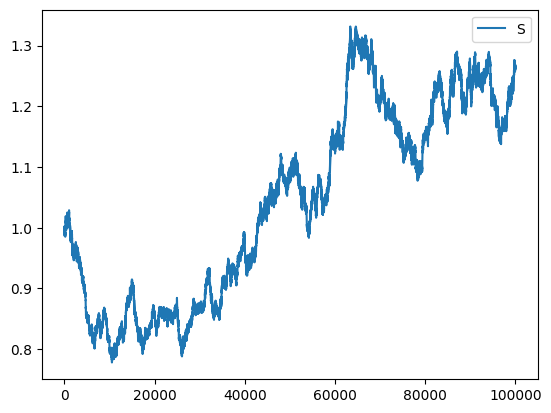

In [5]:
from data_generation.processes import simulate_process
S_, mu_exact_, sigma_exact_ = simulate_process(dW, dt, S0, drift="BS", diff="BS", r=r, sigm=sigm)
plt.plot(S_, label="S")
plt.legend()
plt.show()

##compute quadratic variation

  0%|          | 0/100000 [00:00<?, ?it/s]

 12%|█▏        | 11543/100000 [00:00<00:00, 115413.88it/s]

 23%|██▎       | 23085/100000 [00:00<00:01, 73615.97it/s] 

 31%|███▏      | 31292/100000 [00:00<00:01, 56474.47it/s]

 38%|███▊      | 37608/100000 [00:00<00:01, 50606.82it/s]

...

 93%|█████████▎| 93109/100000 [00:03<00:00, 18579.61it/s]

 95%|█████████▍| 94971/100000 [00:03<00:00, 18205.77it/s]

 97%|█████████▋| 96795/100000 [00:03<00:00, 17975.03it/s]

 99%|█████████▊| 98595/100000 [00:03<00:00, 17818.48it/s]

100%|██████████| 100000/100000 [00:03<00:00, 28424.89it/s]

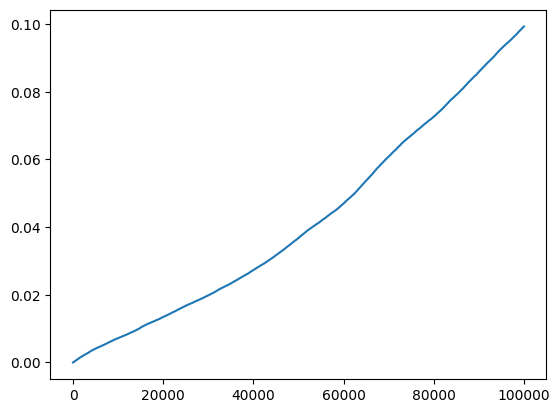

In [6]:
from models.diffusion import estimate_quadratic_variation
QV, dQV, diff_method = estimate_quadratic_variation(S_, t)
plt.plot(QV)

##Approximating $\sigma$

In [7]:
from models.diffusion import fit_diffusion_model
model = fit_diffusion_model(S_, t, dQV)
print(model.equations())


['0.091 x0^2 + -0.002 x0^3']


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/optimizers/sr3.py:390: ConvergenceWarning: SR3._reduce did not converge after 1500 iterations.
  warnings.warn(


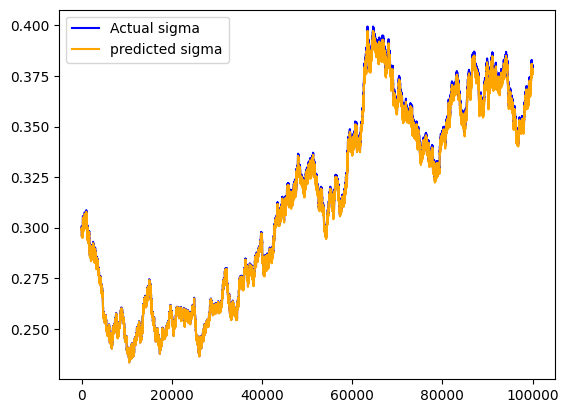

In [8]:
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_pred_ = np.array(sigma_pred_)
plt.plot(sigma_exact_, label="Actual sigma",color="blue")
plt.plot(sigma_pred_,label="predicted sigma", color="orange")
plt.legend()
plt.show()

In [9]:
from models.diffusion import diffusion_derivatives
sigma_prime_, sigma_2prime_, sigma_3prime_ = diffusion_derivatives(sigma_pred_, S_, diff_method)


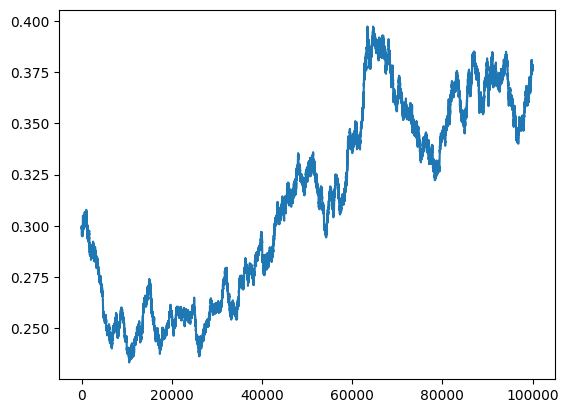

In [10]:
plt.plot(sigma_pred_)

##Q Brownian motion

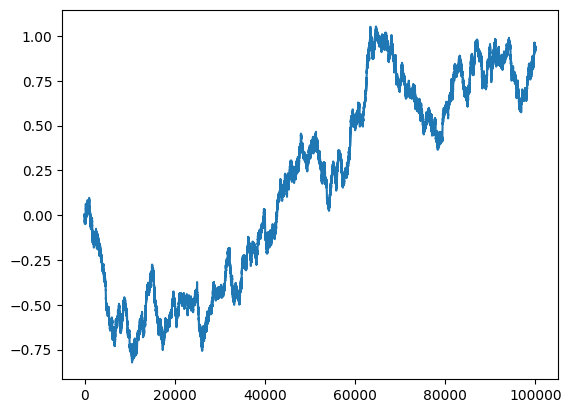

In [11]:
from models.noise import recover_q_noise
BQ_ = recover_q_noise(S_, sigma_pred_)
plt.plot(BQ_)

#Fit signature model

In [12]:
keep_cols = [0, 1, 3, 4, 5, 13]

  0%|          | 0/1000 [00:00<?, ?it/s]

 15%|█▌        | 152/1000 [00:00<00:00, 1411.64it/s]

 29%|██▉       | 294/1000 [00:00<00:00, 769.52it/s] 

 39%|███▊      | 386/1000 [00:00<00:00, 756.36it/s]

 47%|████▋     | 470/1000 [00:00<00:00, 759.09it/s]

...

 71%|███████   | 710/1000 [00:00<00:00, 980.72it/s]

 84%|████████▎ | 836/1000 [00:00<00:00, 1062.24it/s]

 97%|█████████▋| 972/1000 [00:00<00:00, 1147.11it/s]

100%|██████████| 1000/1000 [00:01<00:00, 985.78it/s]

3.529074918675349e-05

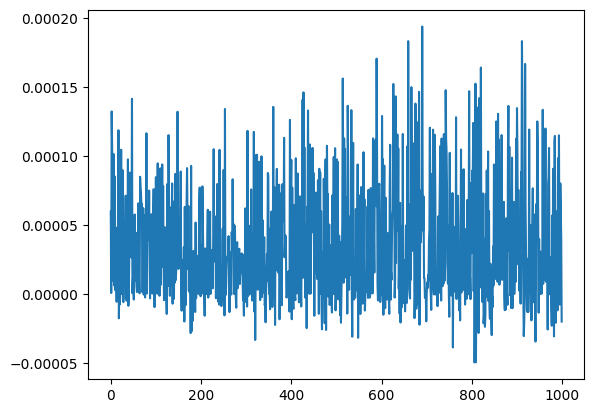

In [13]:
from models.drift import fit_signature
M = 100
K = int(N/M)
l21 = fit_signature(S_, BQ_, t, keep_cols, M)
plt.plot(l21)
np.mean(l21)

In [14]:
from data_generation.coarse_graining import coarse_grain
sigma_pred, mu_exact, S, BQ, W, sigma_exact = coarse_grain(
    S_, BQ_, W_, mu_exact_, sigma_exact_, sigma_pred_, M, K,
)


In [15]:
from models.diffusion import coarse_diffusion_derivatives
sigma_prime, sigma_2prime, sigma_3prime = coarse_diffusion_derivatives(sigma_pred, S, diff_method)


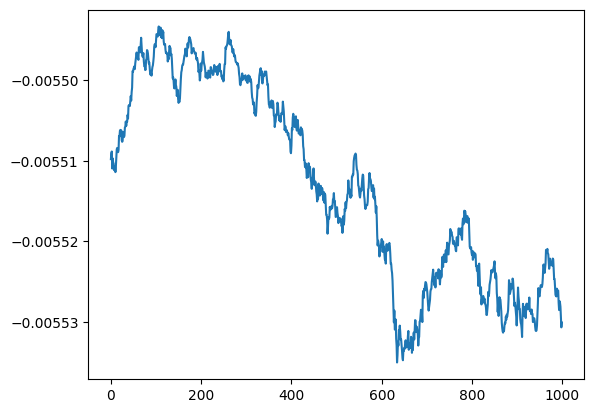

In [16]:
plt.plot(sigma_2prime)

## Predicting $\mu(X_t)$ by tuncating up to level-2 of iterated integrals

In [17]:
from models.drift import drift_coefficients
mu_0, a, b, b_ = drift_coefficients(mu_exact, sigma_pred, sigma_prime, sigma_2prime, l21)


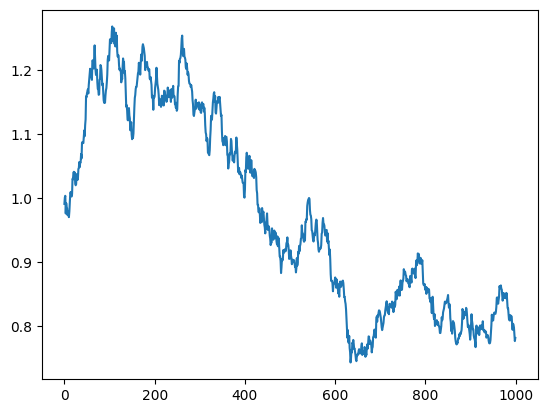

In [18]:
#plt.plot(b)
plt.plot(a)

In [19]:
from models.drift import recover_drift
mu_pred1, mu_pred2 = recover_drift(S, a, b, b_, mu_0)


## Drift recovery from ODE2

Run the ODE2 recovery with the existing coarse data and compare `mu_pred11` with the actual drift `mu_exact`. The initial conditions are `mu_0` and `r`, as in the supplied code.


In [20]:
lambda_0 = r
from models.drift import recover_drift_ode2
mu_pred11, lamda_pred = recover_drift_ode2(S, sigma_pred, sigma_prime, sigma_2prime, mu_0, lambda_0)


In [21]:
ode2_drift_mse = mean_squared_error(mu_exact, mu_pred11)
print(f"ODE2 drift MSE: {ode2_drift_mse:.5f}")
print(f"ODE2 drift RMSE: {np.sqrt(ode2_drift_mse):.5f}")


ODE2 drift MSE: 0.00000
ODE2 drift RMSE: 0.00000


## Drift comparison across all methods

Method 1: drift RMSE = 0.00600
Method 2: drift RMSE = 0.00065
ODE2: drift RMSE = 0.00000


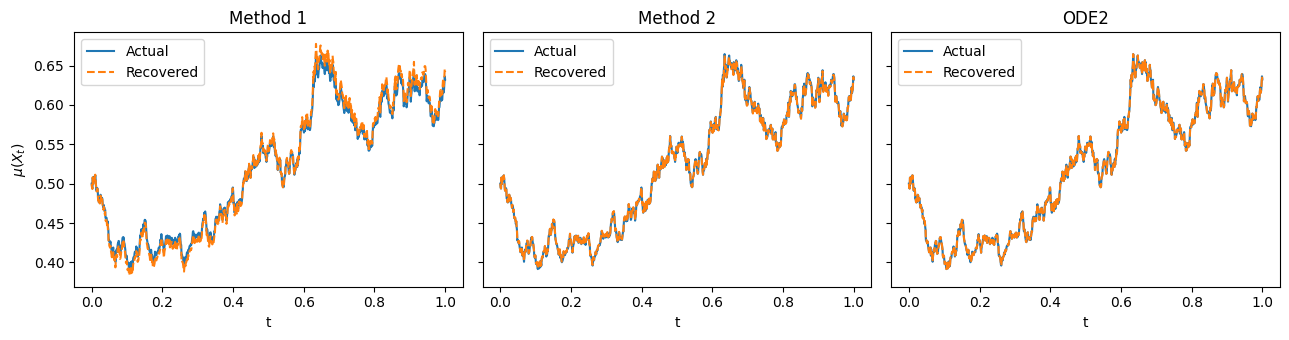

In [22]:
t_ = np.linspace(0, T, K)
drift_estimates = {'Method 1': mu_pred1, 'Method 2': mu_pred2, 'ODE2': mu_pred11}
drift_rmse = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, estimate) in zip(axes, drift_estimates.items()):
    drift_rmse[name] = float(np.sqrt(np.mean((estimate - mu_exact)**2)))
    ax.plot(t_, mu_exact, label='Actual')
    ax.plot(t_, estimate, '--', label='Recovered')
    ax.set_title(name)
    ax.set_xlabel('t')
    ax.legend()
    print(f"{name}: drift RMSE = {drift_rmse[name]:.5f}")
axes[0].set_ylabel(r'$\mu(X_t)$')
fig.tight_layout()
fig.savefig('drift_comparison.png', dpi=200)
plt.show()


##Predicting P-Brownian motion

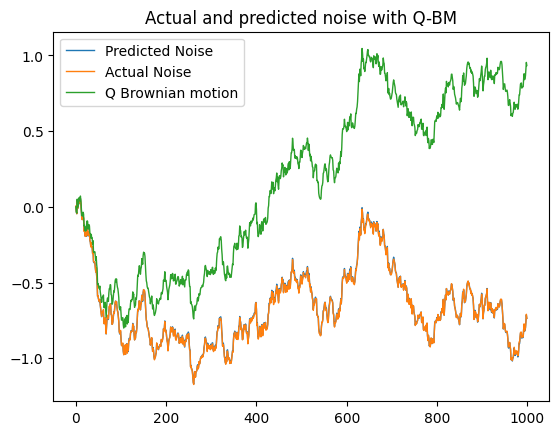

In [23]:
from models.noise import recover_p_noise
model = "Psi_approx_BS"
BP, dt, t = recover_p_noise(BQ, mu_pred1, sigma_pred, T)
plt.plot(BP, label="Predicted Noise", linewidth=1)
plt.plot(W, label="Actual Noise", linewidth=1)
plt.plot(BQ, label="Q Brownian motion", linewidth=1)
plt.title("Actual and predicted noise with Q-BM")
plt.legend()
plt.savefig(f"{model}_Actual and predicted noise with Q-BM.png", bbox_inches='tight', dpi=300)
plt.show()

### Drift from Method 1

MSE: 0.00000
μ(X) = 0.50377*X
σ(X) = 0.00324 + 0.29576*X
[CV best] alpha=0.00039, l1_ratio (rho)=0.85000


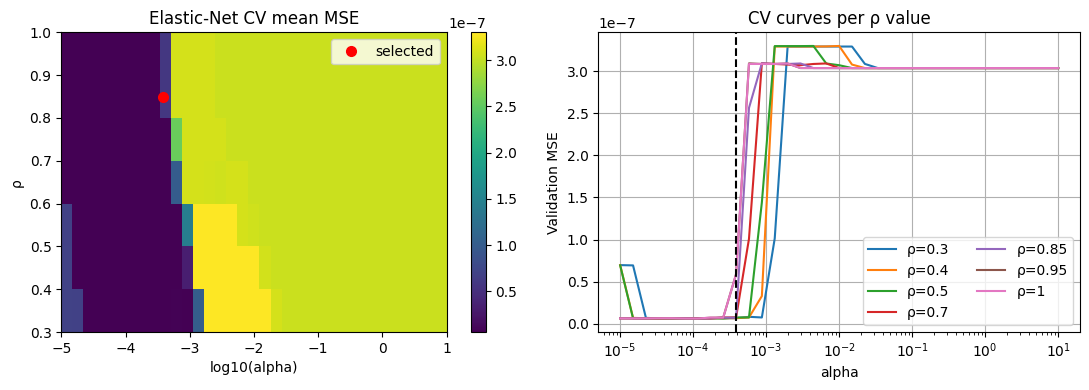

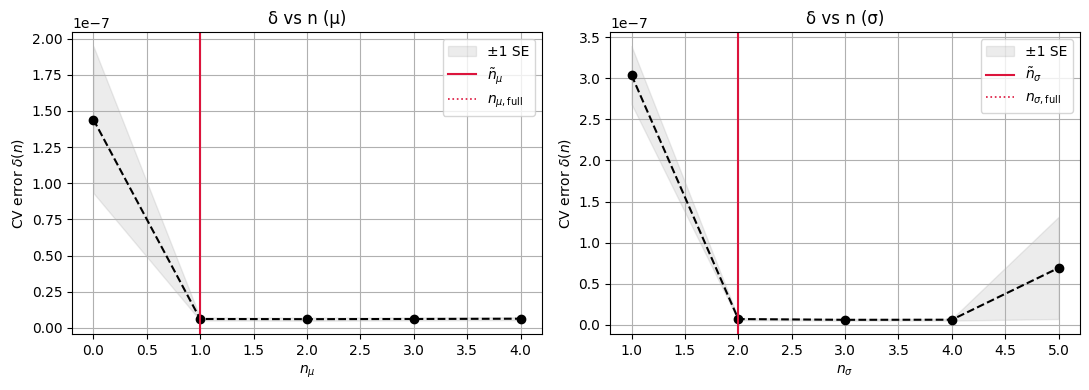

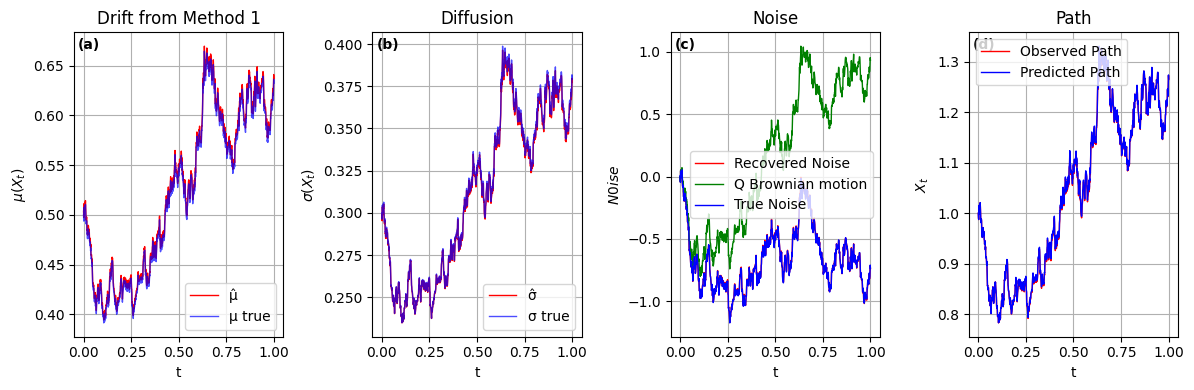

### Drift from Method 2

MSE: 0.00000
μ(X) = 0.50169*X
σ(X) = 0.00318 + 0.29582*X
[CV best] alpha=0.00039, l1_ratio (rho)=0.85000


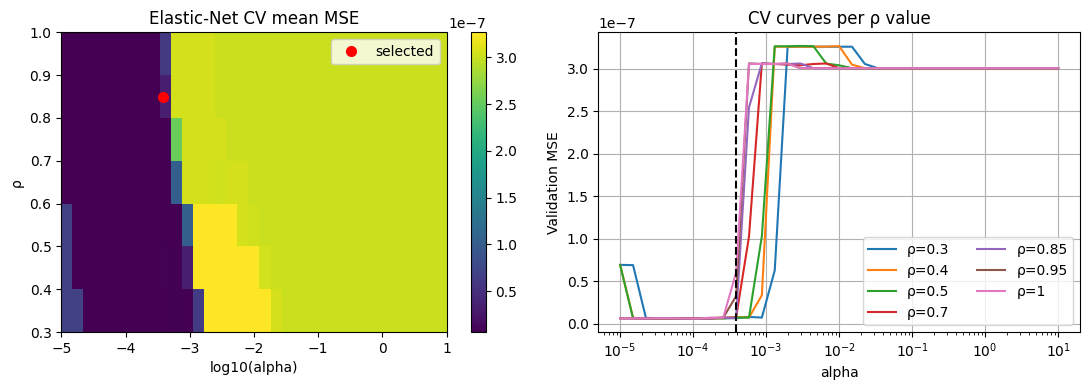

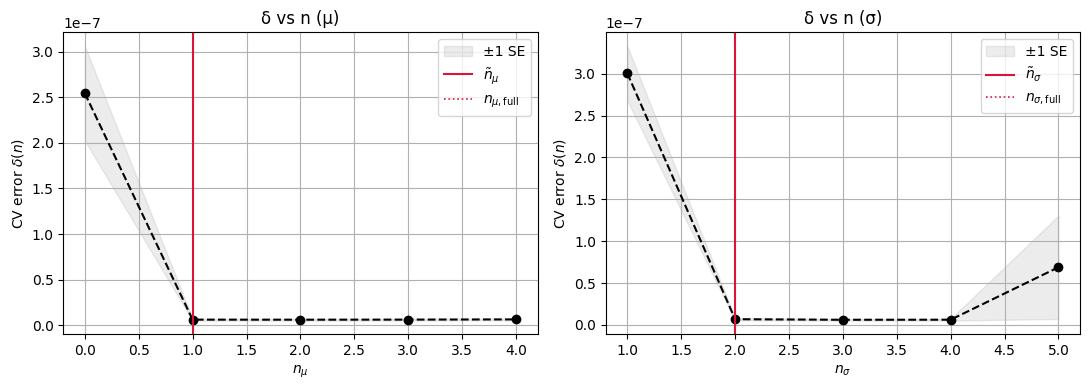

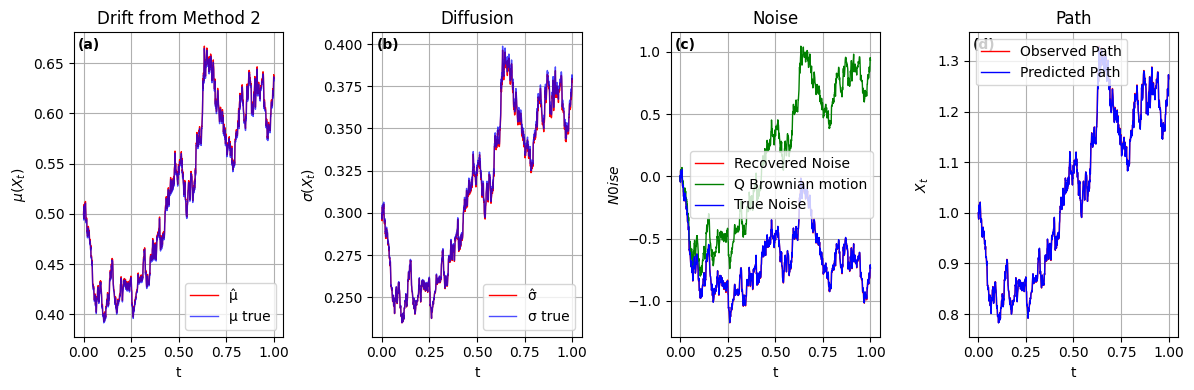

### Drift from ODE2

MSE: 0.00000
μ(X) = 0.50186*X
σ(X) = 0.00319 + 0.29581*X
[CV best] alpha=0.00039, l1_ratio (rho)=0.85000


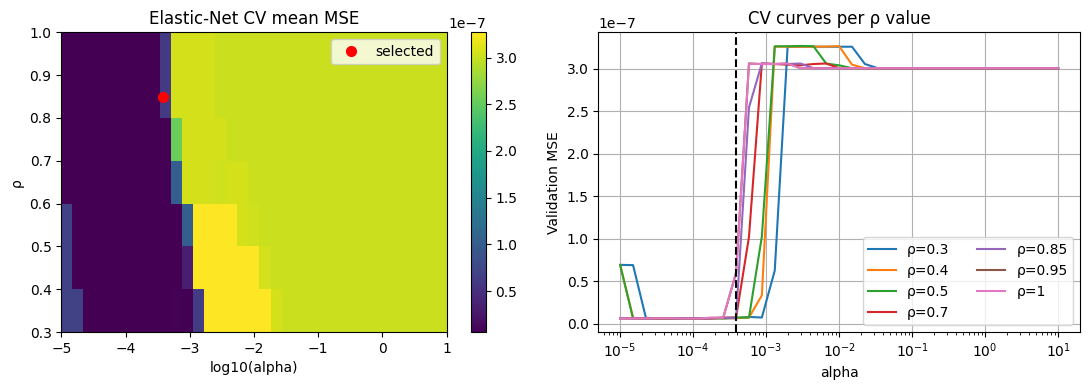

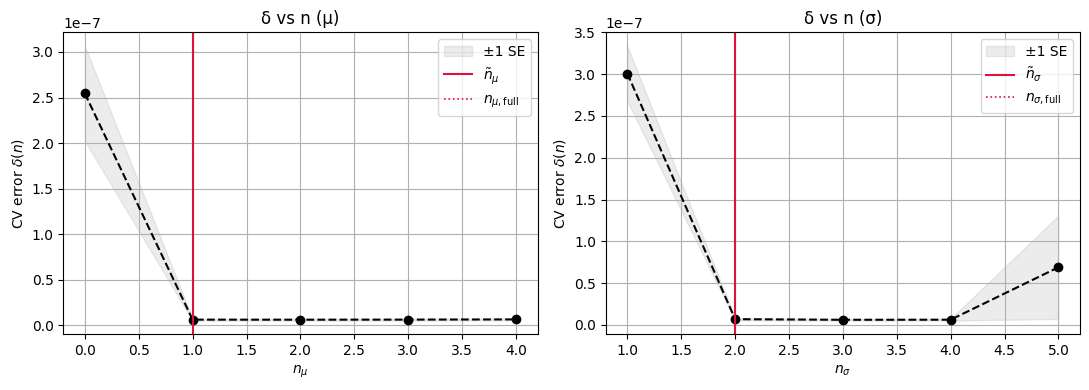

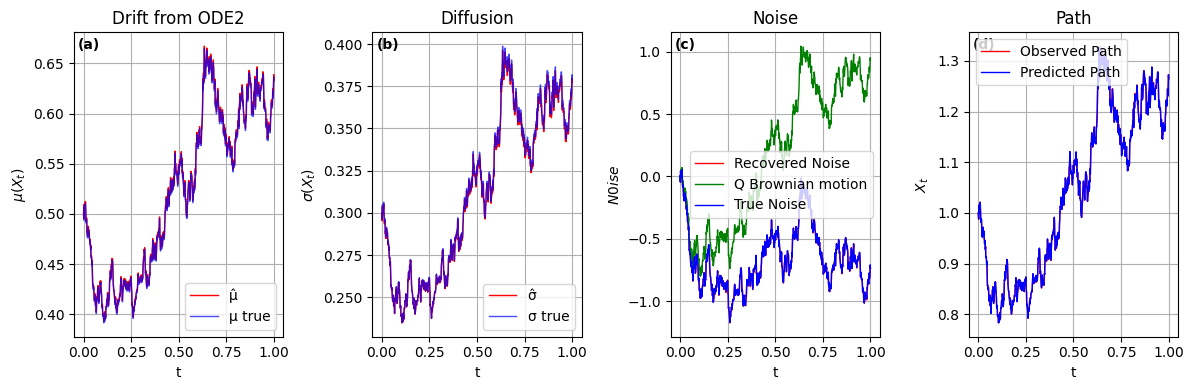

| Noise from | Noise RMSE | SSISDE drift RMSE | SSISDE diffusion RMSE |
|---|---:|---:|---:|
| Method 1 | 0.00520 | 0.00397 | 0.00136 |
| Method 2 | 0.00393 | 0.00178 | 0.00135 |
| ODE2 | 0.00367 | 0.00196 | 0.00135 |

In [24]:
from models.stochastic_sindy import StochSINDy
from models.noise import recover_p_noise
from threadpoolctl import threadpool_limits
from IPython.display import Markdown, display
import json

# Check the exact polynomial metadata against the simulated coefficients.
np.testing.assert_allclose(np.polynomial.polynomial.polyval(S, exact_mu_coefficients), mu_exact)
np.testing.assert_allclose(np.polynomial.polynomial.polyval(S, exact_sigma_coefficients), sigma_exact)
(RESULTS / "model_truth.json").write_text(json.dumps({
    "mu_coefficients": exact_mu_coefficients,
    "sigma_coefficients": exact_sigma_coefficients,
}, indent=2, allow_nan=False))

recovered_drifts = {"Method 1": mu_pred1, "Method 2": mu_pred2, "ODE2": mu_pred11}
identifiers, noise_paths, ssisde_comparison, comparison_paths = {}, {}, {}, {}

for method_name, recovered_drift in recovered_drifts.items():
    method_key = method_name.lower().replace(" ", "_")
    BP_method, dt_method, _ = recover_p_noise(BQ, recovered_drift, sigma_pred, T)
    noise_paths[method_name] = BP_method
    identifier_method = StochSINDy(
        mu_deg=5, si_deg=5,
        pen="elasticnet",
        use_cv=True, k=7,
        alphas=np.geomspace(1e-5, 1e1, 35),
        rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0],
        use_1se=True,
    )
    with threadpool_limits(limits=1):
        identifier_method.fit(S, BP_method, dt_method)
    identifiers[method_name] = identifier_method
    output_prefix = f"{model}_{method_key}"
    display(Markdown(f"### Drift from {method_name}"))
    identifier_method.show()
    identifier_method.plot_cv(output_prefix=output_prefix)
    identifier_method.plot_size(count_bias=True, output_prefix=output_prefix)
    identifier_method.plot_results(
        S, BP_method, BQ, W, mu_true=mu_exact, si_true=sigma_exact,
        output_prefix=output_prefix, drift_title=f"Drift from {method_name}",
    )
    mu_fit = identifier_method.mu(S)
    sigma_fit = identifier_method.si(S)
    ssisde_comparison[method_name] = {
        "input_drift_rmse": float(np.sqrt(np.mean((recovered_drift - mu_exact)**2))),
        "noise_rmse": float(np.sqrt(np.mean((BP_method - W)**2))),
        "drift_rmse": float(np.sqrt(np.mean((mu_fit - mu_exact)**2))),
        "diffusion_rmse": float(np.sqrt(np.mean((sigma_fit - sigma_exact)**2))),
        "increment_mse": identifier_method.mse,
        "mu": identifier_method._fmt_poly(identifier_method.mu_c),
        "sigma": identifier_method._fmt_poly(identifier_method.si_c),
        "mu_coefficients": identifier_method.mu_c.tolist(),
        "sigma_coefficients": identifier_method.si_c.tolist(),
        "mu_coefficients_unrounded": identifier_method.mu_c_unrounded.tolist(),
        "sigma_coefficients_unrounded": identifier_method.si_c_unrounded.tolist(),
        "coefficient_decimals": identifier_method.coefficient_decimals,
        "increment_mse_unrounded": identifier_method.mse_unrounded,
        "alpha": identifier_method.best_a,
        "rho": identifier_method.best_r,
    }
    comparison_paths[f"BP_{method_key}"] = BP_method
    comparison_paths[f"input_drift_{method_key}"] = recovered_drift
    comparison_paths[f"mu_fit_{method_key}"] = mu_fit
    comparison_paths[f"sigma_fit_{method_key}"] = sigma_fit

(RESULTS / "ssisde_comparison.json").write_text(json.dumps(ssisde_comparison, indent=2, allow_nan=False))
np.savez_compressed(RESULTS / "ssisde_comparison_paths.npz", S=S, BQ=BQ, W=W,
                    mu_exact=mu_exact, sigma_exact=sigma_exact, sigma_pred=sigma_pred,
                    dt=dt, **comparison_paths)
rows = ["| Noise from | Noise RMSE | SSISDE drift RMSE | SSISDE diffusion RMSE |",
        "|---|---:|---:|---:|"]
for method_name, values in ssisde_comparison.items():
    rows.append(f"| {method_name} | {values['noise_rmse']:.5f} | "
                f"{values['drift_rmse']:.5f} | {values['diffusion_rmse']:.5f} |")
display(Markdown("\n".join(rows)))
identifier = identifiers["Method 1"]
